## 01 · GridSearchCV 전체 조합 탐색
교재 **226–227쪽**

In [1]:
# 필요한 라이브러리를 불러옵니다.
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 데이터를 불러옵니다.
df = pd.read_csv("Part4 Chapter8 Wine Quality.csv")

# 피처(X)와 타깃(y)을 정의합니다.
X = df.drop(columns=['quality'])
y = df['quality']

# 데이터를 훈련용(80%)과 테스트용(20%)으로 분할합니다.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# 1. 튜닝할 하이퍼파라미터 후보 값들을 딕셔너리로 정의합니다.
param_grid = {
    'n_estimators': [50, 100, 200], # 나무의 개수
    'max_depth': [3, 5, 10, None], # 나무의 최대 깊이 (None: 제한 없음)
    'min_samples_split': [2, 5, 10] # 노드를 분할하기 위한 최소 샘플 수
}

# 2. GridSearchCV 객체를 생성합니다.
# estimator: 튜닝할 모델, param_grid: 탐색할 파라미터 조합
# cv=5: 5-폴드 교차 검증, scoring: 성능 평가 기준
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1 # 모든 CPU 코어를 사용하여 병렬 처리
)

# 3. 훈련 데이터로 모든 조합을 탐색합니다.
grid_search.fit(X_train, y_train)

# 4. 최적의 하이퍼파라미터 조합을 확인합니다.
print("최적 하이퍼파라미터:", grid_search.best_params_)
print("최적 교차 검증 점수:", round(grid_search.best_score_, 4))

# 5. 최적 모델로 테스트 데이터를 예측합니다.
best_model = grid_search.best_estimator_
predictions = best_model.predict(X_test)
print("테스트 정확도:", round(accuracy_score(y_test, predictions), 4))

최적 하이퍼파라미터: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}
최적 교차 검증 점수: 0.6476
테스트 정확도: 0.69


## 02 · RandomizedSearchCV 무작위 탐색
교재 **228–229쪽**

In [2]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint # 정수 범위에서 무작위 샘플링을 위한 도구

# 1. 탐색할 하이퍼파라미터 범위를 정의합니다.
# GridSearchCV와 달리, 하이퍼파라미터 값의 범위를 지정할 수 있습니다.
param_distributions = {
    'n_estimators': randint(50, 300), # 50~299 사이의 정수에서 무작위 선택
    'max_depth': [3, 5, 7, 10, 15, None], # 리스트에서 무작위 선택
    'min_samples_split': randint(2, 20), # 2~19 사이의 정수에서 무작위 선택
    'min_samples_leaf': randint(1, 10) # 1~9 사이의 정수에서 무작위 선택
}

# 2. RandomizedSearchCV 객체를 생성합니다.
# n_iter=30: 무작위로 30가지 조합만 시도합니다.
random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_distributions,
    n_iter=30, # 시도할 조합의 수
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

# 3. 훈련 데이터로 탐색합니다.
random_search.fit(X_train, y_train)

# 4. 최적의 하이퍼파라미터 조합을 확인합니다.
print("최적 하이퍼파라미터:", random_search.best_params_)
print("최적 교차 검증 점수:", round(random_search.best_score_, 4))

# 5. 최적 모델로 테스트 데이터를 예측합니다.
best_model = random_search.best_estimator_
predictions = best_model.predict(X_test)
print("테스트 정확도:", round(accuracy_score(y_test, predictions), 4))

최적 하이퍼파라미터: {'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 8, 'n_estimators': 58}
최적 교차 검증 점수: 0.6323
테스트 정확도: 0.69


## 03 · 콜백으로 학습 중단과 최적 모델 저장
교재 **231–232쪽**

In [3]:
# --- 실습 준비 ---
# 필요한 라이브러리들을 모두 불러옵니다.
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# --- 1. 데이터 준비: 불러오기, 전처리, 분할 ---
# 데이터를 불러옵니다.
df = pd.read_csv("Part4 Chapter7 Insurance.csv")

# smoker(yes/no), sex(male/female) 등 문자형 데이터를 숫자로 변환하기 위해 원-핫 인코딩을 수행합니다.
# drop_first=True는 중복되는 정보를 제거하여 피처의 수를 줄여줍니다(예: sex_male만 있어도 여부 판단 가능).
df = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

# 피처(X)와 타깃(y)을 정의합니다. smoker_yes가 예측해야 할 타깃이 됩니다.
X = df.drop(columns=['smoker_yes'])
y = df['smoker_yes']

# 훈련용 데이터와 테스트용 데이터로 분할합니다.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
random_state=42)

# 피처 데이터를 표준화 스케일링합니다. 딥러닝 모델의 안정적인 학습을 위해 필수적입니다.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- 2. 모델 구현 및 콜백 설정 ---
# 딥러닝 모델의 구조를 설계합니다.
# 첫 번째 은닉층: 32개의 뉴런과 relu 활성화 함수를 사용하며, 입력 피처의 개수(X_train_scaled.shape[1])를 input_shape으로 지정합니다.
# 두 번째 은닉층: 16개의 뉴런과 relu 활성화 함수를 사용하여 데이터의 패턴을 더 깊게 학습합니다.
# 출력층: 흡연 여부(0 또는 1)를 예측하는 이진 분류이므로 뉴런은 1개, 활성화 함수는 sigmoid를 사용합니다.
model = keras.Sequential([
keras.layers.Dense(units=32, activation='relu', input_shape=[X_train_scaled.shape[1]]),
keras.layers.Dense(units=16, activation='relu'),
keras.layers.Dense(units=1, activation='sigmoid')
])

# 모델의 학습 방식을 설정(컴파일)합니다.
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# EarlyStopping 콜백을 설정합니다.
# monitor=’val_loss’: 검증 손실(val_loss)을 관찰합니다.
# patience=5: 5번의 epoch 동안 성능 개선이 없으면 학습을 조기 종료합니다.
# restore_best_weights=True: 학습 중단 시 가장 성능이 좋았던 시점의 모델 가중치로 되돌립니다.
es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# ModelCheckpoint 콜백을 설정합니다.
# ‘best_smoker_model.keras’: 가장 좋은 모델이 저장될 파일 이름입니다.
# save_best_only=True: val_loss가 이전보다 개선될 때만 모델을 저장합니다.
mc = ModelCheckpoint('best_smoker_model.keras', monitor='val_loss', save_best_only=True)

# --- 3. 모델 학습 실행(콜백 적용) ---
print("콜백을 적용하여 모델 학습을 시작합니다...")

# model.fit에 callbacks 리스트를 전달하여 학습을 시작합니다.
history = model.fit(X_train_scaled, y_train, 
    epochs=100, # epochs를 넉넉하게 100으로 설정
    validation_data=(X_test_scaled, y_test),
    callbacks=[es, mc]) # 준비된 콜백들을 리스트에 담아 전달

콜백을 적용하여 모델 학습을 시작합니다...
Epoch 1/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7935 - loss: 0.5438 - val_accuracy: 0.8507 - val_loss: 0.4603
Epoch 2/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8654 - loss: 0.4024 - val_accuracy: 0.8881 - val_loss: 0.3333
Epoch 3/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8935 - loss: 0.2980 - val_accuracy: 0.9067 - val_loss: 0.2430
Epoch 4/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9000 - loss: 0.2275 - val_accuracy: 0.9030 - val_loss: 0.1865
Epoch 5/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9019 - loss: 0.1809 - val_accuracy: 0.9142 - val_loss: 0.1543
Epoch 6/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9252 - loss: 0.1514 - val_accuracy: 0.9328 - val_loss: 0.1337
Epoch 7/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9430 - loss: 0.1338 - val_accuracy: 0.9515 - val_loss: 0.1204
Epoch 8/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9495 - loss: 0.1229 -

## 04 · 손실·정확도 학습 곡선
교재 **233–234쪽**

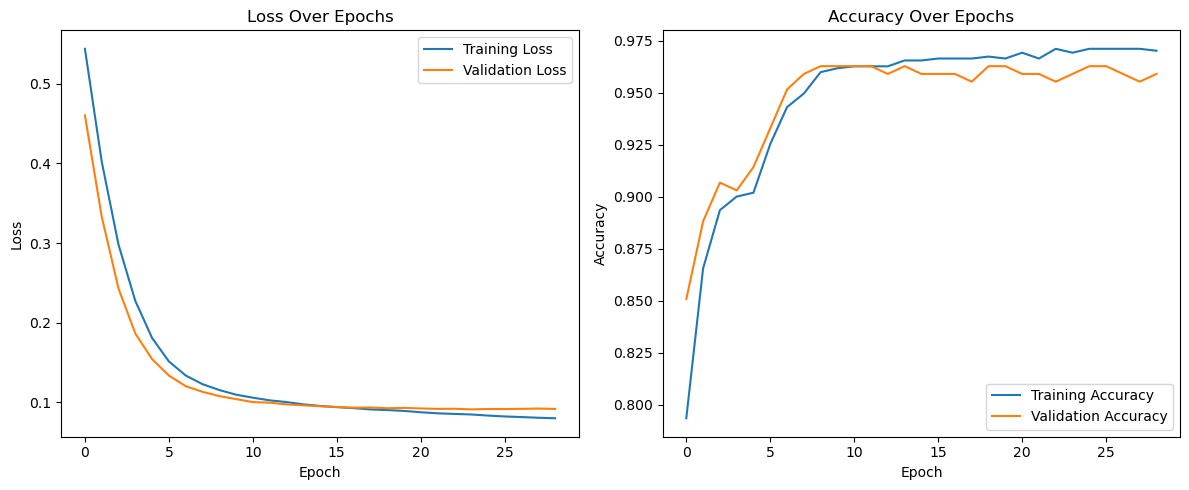

In [4]:
# model.fit()의 반환값으로 저장한 history 객체를 사용합니다.
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 손실(Loss) 그래프를 그립니다.
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1) # 1행 2열의 그래프 중 첫 번째 칸에 그립니다.

# 훈련 데이터의 손실(loss)을 그립니다. (학습이 진행될수록 감소해야 함)
plt.plot(history.history['loss'], label='Training Loss')

# 검증 데이터의 손실(val_loss)을 그립니다. (훈련 데이터와 비슷하게 감소해야 함)
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# 2. 정확도(Accuracy) 그래프를 그립니다.
plt.subplot(1, 2, 2) # 1행 2열의 그래프 중 두 번째 칸에 그립니다.

# 훈련 데이터의 정확도(accuracy)를 그립니다. (학습이 진행될수록 증가해야 함)
plt.plot(history.history['accuracy'], label='Training Accuracy')

# 검증 데이터의 정확도(val_accuracy)를 그립니다. (훈련 데이터와 비슷하게 증가해야 함)
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout() # 그래프 간 간격을 자동으로 조절해줍니다.
plt.show()